# **Machine Learning Framework for SMS Spam Detection Using TF-IDF**

**Data file** https://docs.google.com/spreadsheets/d/161yp4eQNi4WQvjN7xi8EsKXy21zh08qKzd50WQmGW0Q/edit?usp=sharing

#4.1 Dataset Analysis, Cleaning and Class Imbalance
Conference-paper experiment. Run top to bottom in Google Colab. This notebook does not train any classifier.

##4.1.1 Dataset Loading and Validation

In [1]:
import pandas as pd
from google.colab import files
import io

# Step 1: Upload file from your computer
uploaded = files.upload()

# Step 2: Get uploaded filename automatically
filename = next(iter(uploaded))

# Step 3: Read dataset based on file extension
if filename.endswith('.xlsx') or filename.endswith('.xls'):
    df = pd.read_excel(io.BytesIO(uploaded[filename]))
else:
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Step 4: Display dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

# Adjust 'label' printing if 'label' column exists
if "label" in df.columns:
    print("\nClass distribution:")
    print(df["label"].value_counts())
else:
    print("\nNote: 'label' column not found in this dataset.")

Saving SMS_cleaned_5216.xlsx to SMS_cleaned_5216.xlsx
Dataset shape: (5216, 3)

Column names:
['label', 'message', 'source']

First five rows:
  label                                            message    source
0   ham  Go until jurong point, crazy.. Available only ...  Original
1   ham                      Ok lar... Joking wif u oni...  Original
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...  Original
3   ham  U dun say so early hor... U c already then say...  Original
4   ham  Nah I don't think he goes to usf, he lives aro...  Original

Missing values:
label      0
message    0
source     0
dtype: int64

Class distribution:
label
ham     4531
spam     685
Name: count, dtype: int64


**#4.2 Dataset Partitioning and Cross-Validation**

### 4.2.1 Stratified Training–Testing Split

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold

# Use the cleaned dataset from Section 4.1
X = df["message"].astype(str)
y = df["label"].map({"ham": 0, "spam": 1})

assert y.notna().all(), "Unexpected class labels detected"

print("Total SMS messages:", len(X))
print("Ham messages:", (y == 0).sum())
print("Spam messages:", (y == 1).sum())

Total SMS messages: 5216
Ham messages: 4531
Spam messages: 685


In [3]:
from sklearn.model_selection import train_test_split

# Input features and target labels
X = df["message"].astype(str)
y = df["label"].map({"ham": 0, "spam": 1})

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total dataset:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index().rename(index={0: "Ham", 1: "Spam"}))

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index().rename(index={0: "Ham", 1: "Spam"}))

Total dataset: 5216
Training samples: 4172
Testing samples: 1044

Training class distribution:
label
Ham     3624
Spam     548
Name: count, dtype: int64

Testing class distribution:
label
Ham     907
Spam    137
Name: count, dtype: int64


###4.2.2 Dataset Partition Distribution

In [4]:
import pandas as pd

table2 = pd.DataFrame({
    "Partition": ["Training", "Testing", "Complete Dataset"],
    "Ham": [
        (y_train == 0).sum(),
        (y_test == 0).sum(),
        (y == 0).sum()
    ],
    "Spam": [
        (y_train == 1).sum(),
        (y_test == 1).sum(),
        (y == 1).sum()
    ]
})

table2["Total"] = table2["Ham"] + table2["Spam"]
table2["Ham (%)"] = (table2["Ham"] / table2["Total"] * 100).round(2)
table2["Spam (%)"] = (table2["Spam"] / table2["Total"] * 100).round(2)

print(table2.to_string(index=False))

table2.to_csv("Table_2_Dataset_Partitioning.csv", index=False)

       Partition  Ham  Spam  Total  Ham (%)  Spam (%)
        Training 3624   548   4172    86.86     13.14
         Testing  907   137   1044    86.88     13.12
Complete Dataset 4531   685   5216    86.87     13.13


###4.2.3 Stratified Five-Fold Cross-Validation

In [5]:
from sklearn.model_selection import StratifiedKFold
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    fold_results.append({
        "Fold": fold,
        "Training Samples": len(train_idx),
        "Validation Samples": len(val_idx),
        "Training Ham": (y_tr == 0).sum(),
        "Training Spam": (y_tr == 1).sum(),
        "Validation Ham": (y_val == 0).sum(),
        "Validation Spam": (y_val == 1).sum(),
        "Validation Spam (%)": round(
            (y_val == 1).mean() * 100, 2
        )
    })

fold_table = pd.DataFrame(fold_results)

print(fold_table.to_string(index=False))

fold_table.to_csv(
    "Table_CV_Fold_Distribution.csv",
    index=False
)

 Fold  Training Samples  Validation Samples  Training Ham  Training Spam  Validation Ham  Validation Spam  Validation Spam (%)
    1              3337                 835          2899            438             725              110                13.17
    2              3337                 835          2899            438             725              110                13.17
    3              3338                 834          2899            439             725              109                13.07
    4              3338                 834          2899            439             725              109                13.07
    5              3338                 834          2900            438             724              110                13.19


**#4.3 Baseline Machine Learning Model Evaluation**

###4.3.1 TF-IDF Feature Extraction

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB

# Configure TF-IDF
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    norm="l2"
)

# Create an example ML pipeline
pipeline_nb = Pipeline([
    ("tfidf", tfidf),
    ("classifier", MultinomialNB())
])

print("TF-IDF configuration:")
print(tfidf)

print("\nMachine Learning Pipeline:")
print(pipeline_nb)

TF-IDF configuration:
TfidfVectorizer(max_df=0.95, min_df=2, ngram_range=(1, 2))

Machine Learning Pipeline:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, min_df=2, ngram_range=(1, 2))),
                ('classifier', MultinomialNB())])


###4.3.2 Baseline Classifier Configuration

In [7]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Define five baseline classifiers
models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

print("Baseline Machine Learning Classifiers:\n")

for name, model in models.items():
    print(name, ":", model)

Baseline Machine Learning Classifiers:

Multinomial Naive Bayes : MultinomialNB()
Logistic Regression : LogisticRegression(max_iter=1000, random_state=42)
Linear SVM : LinearSVC(random_state=42)
Random Forest : RandomForestClassifier(n_jobs=-1, random_state=42)
Decision Tree : DecisionTreeClassifier(random_state=42)


###4.3.3 Classification Performance Metrics

In [8]:
from sklearn.metrics import make_scorer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    average_precision_score
)

# Evaluation metrics for binary classification
# Ham = 0, Spam = 1

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "Balanced_Accuracy": "balanced_accuracy",
    "MCC": make_scorer(matthews_corrcoef),
    "AP": "average_precision"
}

print("Configured Evaluation Metrics:\n")

for metric_name, scorer in scoring.items():
    print(metric_name, ":", scorer)

Configured Evaluation Metrics:

Accuracy : accuracy
Precision : precision
Recall : recall
F1 : f1
Balanced_Accuracy : balanced_accuracy
MCC : make_scorer(matthews_corrcoef, response_method='predict')
AP : average_precision


###Step 4.3.4 — Five-Fold Cross-Validation of Baseline Classifiers

In [9]:
import pandas as pd
import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_validate

# Store results of five baseline classifiers
baseline_results = []

for name, model in models.items():

    print(f"\nEvaluating: {name}")

    # Create TF-IDF + classifier pipeline
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            norm="l2"
        )),
        ("classifier", model)
    ])

    start = time.time()

    # Stratified 5-fold cross-validation
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    elapsed_time = time.time() - start

    # Store mean and standard deviation
    result = {"Model": name}

    for metric in scoring.keys():
        result[f"{metric}_Mean"] = scores[
            f"test_{metric}"
        ].mean()

        result[f"{metric}_Std"] = scores[
            f"test_{metric}"
        ].std()

    result["Time_Seconds"] = elapsed_time

    baseline_results.append(result)

    print(f"Completed in {elapsed_time:.2f} seconds")

# Convert results into a DataFrame
baseline_df = pd.DataFrame(baseline_results)

# Display selected performance metrics
display_columns = [
    "Model",
    "Accuracy_Mean",
    "Precision_Mean",
    "Recall_Mean",
    "F1_Mean",
    "Balanced_Accuracy_Mean",
    "MCC_Mean",
    "AP_Mean"
]

print("\nBaseline Classifier Performance:")
print(
    baseline_df[display_columns]
    .round(4)
    .to_string(index=False)
)

# Save complete results
baseline_df.to_csv(
    "Table_3_Baseline_Classifiers.csv",
    index=False
)

print("\nResults saved successfully.")


Evaluating: Multinomial Naive Bayes
Completed in 3.03 seconds

Evaluating: Logistic Regression
Completed in 3.51 seconds

Evaluating: Linear SVM
Completed in 3.58 seconds

Evaluating: Random Forest
Completed in 14.79 seconds

Evaluating: Decision Tree
Completed in 3.92 seconds

Baseline Classifier Performance:
                  Model  Accuracy_Mean  Precision_Mean  Recall_Mean  F1_Mean  Balanced_Accuracy_Mean  MCC_Mean  AP_Mean
Multinomial Naive Bayes         0.9592          1.0000       0.6897   0.8157                  0.8448    0.8114   0.9554
    Logistic Regression         0.9585          0.9925       0.6897   0.8136                  0.8445    0.8079   0.9664
             Linear SVM         0.9844          0.9837       0.8961   0.9376                  0.9469    0.9302   0.9740
          Random Forest         0.9696          0.9976       0.7700   0.8690                  0.8849    0.8614   0.9636
          Decision Tree         0.9566          0.8598       0.8048   0.8300           

In [10]:
# Display mean ± standard deviation for key metrics

for _, row in baseline_df.iterrows():
    print(f"\n{row['Model']}")

    for metric in ["Accuracy", "Precision", "Recall",
                   "F1", "Balanced_Accuracy", "MCC", "AP"]:

        mean = row[f"{metric}_Mean"]
        std = row[f"{metric}_Std"]

        print(f"{metric:20s}: {mean:.4f} ± {std:.4f}")


Multinomial Naive Bayes
Accuracy            : 0.9592 ± 0.0052
Precision           : 1.0000 ± 0.0000
Recall              : 0.6897 ± 0.0402
F1                  : 0.8157 ± 0.0279
Balanced_Accuracy   : 0.8448 ± 0.0201
MCC                 : 0.8114 ± 0.0259
AP                  : 0.9554 ± 0.0243

Logistic Regression
Accuracy            : 0.9585 ± 0.0018
Precision           : 0.9925 ± 0.0099
Recall              : 0.6897 ± 0.0197
F1                  : 0.8136 ± 0.0108
Balanced_Accuracy   : 0.8445 ± 0.0094
MCC                 : 0.8079 ± 0.0089
AP                  : 0.9664 ± 0.0182

Linear SVM
Accuracy            : 0.9844 ± 0.0063
Precision           : 0.9837 ± 0.0124
Recall              : 0.8961 ± 0.0391
F1                  : 0.9376 ± 0.0262
Balanced_Accuracy   : 0.9469 ± 0.0202
MCC                 : 0.9302 ± 0.0287
AP                  : 0.9740 ± 0.0154

Random Forest
Accuracy            : 0.9696 ± 0.0028
Precision           : 0.9976 ± 0.0047
Recall              : 0.7700 ± 0.0207
F1             

###4.3.5 Comparative Performance of Baseline Classifiers

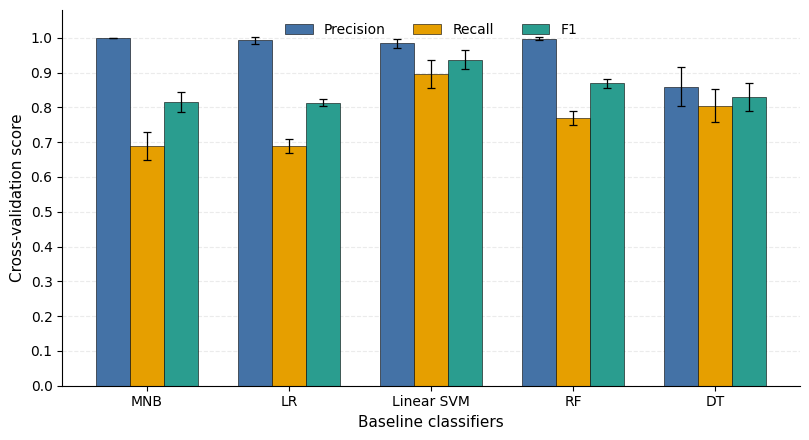

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Abbreviated classifier names
model_names = ["MNB", "LR", "Linear SVM", "RF", "DT"]

metrics = ["Precision", "Recall", "F1"]
colors = ["#4472A6", "#E69F00", "#2A9D8F"]

x = np.arange(len(model_names))
width = 0.24

fig, ax = plt.subplots(figsize=(8.2, 4.5))

for i, (metric, color) in enumerate(zip(metrics, colors)):

    means = baseline_df[f"{metric}_Mean"].to_numpy()
    stds = baseline_df[f"{metric}_Std"].to_numpy()

    ax.bar(
        x + (i - 1) * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=metric,
        color=color,
        edgecolor="black",
        linewidth=0.4,
        error_kw={"elinewidth": 0.9, "capthick": 0.9}
    )

ax.set_ylabel("Cross-validation score", fontsize=11)
ax.set_xlabel("Baseline classifiers", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=10)

ax.set_ylim(0, 1.08)

ax.set_yticks(np.arange(0, 1.01, 0.1))

ax.legend(
    loc="upper center",
    ncol=3,
    frameon=False,
    fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save publication-quality versions
plt.savefig(
    "Figure_2_Baseline_Classifier_Comparison.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "Figure_2_Baseline_Classifier_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

###**Section 4.4 — Class-Weighted Classifier Evaluation**

###4.4.1 Configuration of Class-Weighted Classifiers

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

weighted_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    )
}

print("Class-Weighted Classifiers:\n")

for name, model in weighted_models.items():
    print(name, ":", model)

Class-Weighted Classifiers:

Logistic Regression : LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
Linear SVM : LinearSVC(class_weight='balanced', random_state=42)
Random Forest : RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)
Decision Tree : DecisionTreeClassifier(class_weight='balanced', random_state=42)


###Step 4.4.2 — Evaluate Class-Weighted Classifiers Using 5-Fold Cross-Validation

In [13]:
import pandas as pd
import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_validate

weighted_results = []

for name, model in weighted_models.items():

    print(f"\nEvaluating Class-Weighted: {name}")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            norm="l2"
        )),
        ("classifier", model)
    ])

    start = time.time()

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    elapsed_time = time.time() - start

    result = {"Model": name}

    for metric in scoring.keys():

        result[f"{metric}_Mean"] = scores[
            f"test_{metric}"
        ].mean()

        result[f"{metric}_Std"] = scores[
            f"test_{metric}"
        ].std()

    result["Time_Seconds"] = elapsed_time

    weighted_results.append(result)

    print(f"Completed in {elapsed_time:.2f} seconds")

# Convert results to DataFrame
weighted_df = pd.DataFrame(weighted_results)

# Display all seven metrics
display_columns = [
    "Model",
    "Accuracy_Mean",
    "Precision_Mean",
    "Recall_Mean",
    "F1_Mean",
    "Balanced_Accuracy_Mean",
    "MCC_Mean",
    "AP_Mean"
]

print("\nClass-Weighted Classifier Performance:")

print(
    weighted_df[display_columns]
    .round(4)
    .to_string(index=False)
)

# Save results
weighted_df.to_csv(
    "Table_4_Class_Weighted_Results.csv",
    index=False
)

print("\nResults saved successfully.")


Evaluating Class-Weighted: Logistic Regression
Completed in 1.43 seconds

Evaluating Class-Weighted: Linear SVM
Completed in 1.12 seconds

Evaluating Class-Weighted: Random Forest
Completed in 10.56 seconds

Evaluating Class-Weighted: Decision Tree
Completed in 2.86 seconds

Class-Weighted Classifier Performance:
              Model  Accuracy_Mean  Precision_Mean  Recall_Mean  F1_Mean  Balanced_Accuracy_Mean  MCC_Mean  AP_Mean
Logistic Regression         0.9789          0.9113       0.9307   0.9206                  0.9585    0.9087   0.9667
         Linear SVM         0.9837          0.9632       0.9107   0.9360                  0.9527    0.9273   0.9716
      Random Forest         0.9662          0.9976       0.7446   0.8525                  0.8721    0.8454   0.9564
      Decision Tree         0.9168          0.6509       0.8103   0.7202                  0.8716    0.6789   0.6326

Results saved successfully.


###4.4.3 Class-Weighted Model Performance Summary

In [14]:
print("Class-Weighted Models: Mean ± Standard Deviation\n")

for _, row in weighted_df.iterrows():

    print(f"\n{row['Model']}")

    for metric in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Balanced_Accuracy",
        "MCC",
        "AP"
    ]:
        mean = row[f"{metric}_Mean"]
        std = row[f"{metric}_Std"]

        print(f"{metric:20s}: {mean:.4f} ± {std:.4f}")

Class-Weighted Models: Mean ± Standard Deviation


Logistic Regression
Accuracy            : 0.9789 ± 0.0070
Precision           : 0.9113 ± 0.0306
Recall              : 0.9307 ± 0.0323
F1                  : 0.9206 ± 0.0260
Balanced_Accuracy   : 0.9585 ± 0.0171
MCC                 : 0.9087 ± 0.0301
AP                  : 0.9667 ± 0.0185

Linear SVM
Accuracy            : 0.9837 ± 0.0045
Precision           : 0.9632 ± 0.0098
Recall              : 0.9107 ± 0.0289
F1                  : 0.9360 ± 0.0181
Balanced_Accuracy   : 0.9527 ± 0.0147
MCC                 : 0.9273 ± 0.0203
AP                  : 0.9716 ± 0.0166

Random Forest
Accuracy            : 0.9662 ± 0.0035
Precision           : 0.9976 ± 0.0049
Recall              : 0.7446 ± 0.0254
F1                  : 0.8525 ± 0.0169
Balanced_Accuracy   : 0.8721 ± 0.0128
MCC                 : 0.8454 ± 0.0166
AP                  : 0.9564 ± 0.0184

Decision Tree
Accuracy            : 0.9168 ± 0.0126
Precision           : 0.6509 ± 0.0556
Recall       

**#4.5 Model Stability Analysis**

###**Step 4.5.1 — F1-Score Stability of Class-Weighted Models**

In [15]:
print("F1-Score Stability Analysis")
print("-" * 70)

for _, row in weighted_df.iterrows():

    mean = row["F1_Mean"]
    std = row["F1_Std"]

    cv_percent = (std / mean) * 100

    print(
        f"{row['Model']:22s} "
        f"Mean = {mean:.4f}  "
        f"SD = {std:.4f}  "
        f"CV = {cv_percent:.2f}%"
    )

F1-Score Stability Analysis
----------------------------------------------------------------------
Logistic Regression    Mean = 0.9206  SD = 0.0260  CV = 2.82%
Linear SVM             Mean = 0.9360  SD = 0.0181  CV = 1.94%
Random Forest          Mean = 0.8525  SD = 0.0169  CV = 1.98%
Decision Tree          Mean = 0.7202  SD = 0.0323  CV = 4.49%


###Step 4.5.2 — Compare Baseline and Class-Weighted Stability

In [16]:
import pandas as pd

# Baseline results from Section 4.3
baseline_f1 = {
    "Logistic Regression": (0.8136, 0.0108),
    "Linear SVM": (0.9376, 0.0262),
    "Random Forest": (0.8630, 0.0183),
    "Decision Tree": (0.8078, 0.0269)
}

comparison = []

for _, row in weighted_df.iterrows():

    model = row["Model"]

    baseline_mean, baseline_sd = baseline_f1[model]

    weighted_mean = row["F1_Mean"]
    weighted_sd = row["F1_Std"]

    baseline_cv = baseline_sd / baseline_mean * 100
    weighted_cv = weighted_sd / weighted_mean * 100

    comparison.append({
        "Model": model,
        "Baseline CV (%)": baseline_cv,
        "Weighted CV (%)": weighted_cv,
        "CV Change (pp)": weighted_cv - baseline_cv
    })

stability_df = pd.DataFrame(comparison)

print("\nBaseline vs Class-Weighted F1 Stability\n")

print(
    stability_df.round(3).to_string(index=False)
)


Baseline vs Class-Weighted F1 Stability

              Model  Baseline CV (%)  Weighted CV (%)  CV Change (pp)
Logistic Regression            1.327            2.821           1.494
         Linear SVM            2.794            1.936          -0.858
      Random Forest            2.121            1.981          -0.139
      Decision Tree            3.330            4.488           1.158


###4.5.3 Fold-Wise F1-Score Analysis

In [17]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

fold_results = []

for name, model in weighted_models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            norm="l2"
        )),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={"F1": "f1"},
        n_jobs=1,
        error_score="raise"
    )

    fold_results.append({
        "Model": name,
        **{
            f"Fold {i+1}": score
            for i, score in enumerate(scores["test_F1"])
        }
    })

fold_df = pd.DataFrame(fold_results)

print("\nFold-wise F1-Scores:")
print(fold_df.round(4).to_string(index=False))


Fold-wise F1-Scores:
              Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5
Logistic Regression  0.9406  0.9279  0.9259  0.9386  0.8700
         Linear SVM  0.9484  0.9346  0.9340  0.9585  0.9048
      Random Forest  0.8601  0.8360  0.8404  0.8821  0.8438
      Decision Tree  0.7149  0.7679  0.7016  0.7422  0.6744


#**4.6 Decision Threshold Optimization**

###Step 4.6.1 — Generate Out-of-Fold Decision Scores

In [18]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Models selected for threshold optimization
threshold_models = {
    "Baseline Linear SVM": LinearSVC(
        random_state=42
    ),

    "Weighted Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

oof_scores = {}

for name, model in threshold_models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            norm="l2"
        )),
        ("classifier", model)
    ])

    method = (
        "decision_function"
        if name == "Baseline Linear SVM"
        else "predict_proba"
    )

    scores = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        method=method,
        n_jobs=1
    )

    # Extract spam probability for Logistic Regression
    if method == "predict_proba":
        scores = scores[:, 1]

    oof_scores[name] = scores

    print(f"\n{name}")
    print("Number of OOF scores:", len(scores))
    print("Minimum score:", round(scores.min(), 4))
    print("Maximum score:", round(scores.max(), 4))

print("\nOut-of-fold score generation completed.")


Baseline Linear SVM
Number of OOF scores: 4172
Minimum score: -2.0039
Maximum score: 2.3971

Weighted Logistic Regression
Number of OOF scores: 4172
Minimum score: 0.0111
Maximum score: 0.9946

Out-of-fold score generation completed.


###Step 4.6.2 — Find the F1-Optimal Threshold

In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []
threshold_curves = {}

for name, scores in oof_scores.items():

    precision, recall, thresholds = precision_recall_curve(
        y_train,
        scores,
        pos_label=1
    )

    # Last precision/recall pair has no corresponding threshold
    p = precision[:-1]
    r = recall[:-1]

    f1 = 2 * p * r / (p + r + 1e-12)

    best_idx = np.argmax(f1)
    best_threshold = thresholds[best_idx]

    default_threshold = (
        0.0 if "SVM" in name else 0.5
    )

    default_predictions = (
        scores >= default_threshold
    ).astype(int)

    optimized_predictions = (
        scores >= best_threshold
    ).astype(int)

    result = {
        "Model": name,
        "Default Threshold": default_threshold,
        "Optimal Threshold": best_threshold,
        "Default Precision": precision_score(
            y_train, default_predictions
        ),
        "Optimal Precision": precision_score(
            y_train, optimized_predictions
        ),
        "Default Recall": recall_score(
            y_train, default_predictions
        ),
        "Optimal Recall": recall_score(
            y_train, optimized_predictions
        ),
        "Default F1": f1_score(
            y_train, default_predictions
        ),
        "Optimal F1": f1_score(
            y_train, optimized_predictions
        )
    }

    threshold_results.append(result)

    threshold_curves[name] = {
        "thresholds": thresholds,
        "precision": p,
        "recall": r,
        "f1": f1
    }

threshold_df = pd.DataFrame(threshold_results)

print("\nOOF Threshold Optimization Results:\n")

print(
    threshold_df.round(4).to_string(index=False)
)

threshold_df.to_csv(
    "Threshold_Optimization_Results.csv",
    index=False
)

print("\nThreshold optimization results saved.")


OOF Threshold Optimization Results:

                       Model  Default Threshold  Optimal Threshold  Default Precision  Optimal Precision  Default Recall  Optimal Recall  Default F1  Optimal F1
         Baseline Linear SVM                0.0            -0.1805             0.9840             0.9583          0.8960          0.9234      0.9379      0.9405
Weighted Logistic Regression                0.5             0.5655             0.9107             0.9455          0.9307          0.9179      0.9206      0.9315

Threshold optimization results saved.


###Step 4.6.3 Threshold–F1 Performance Analysis

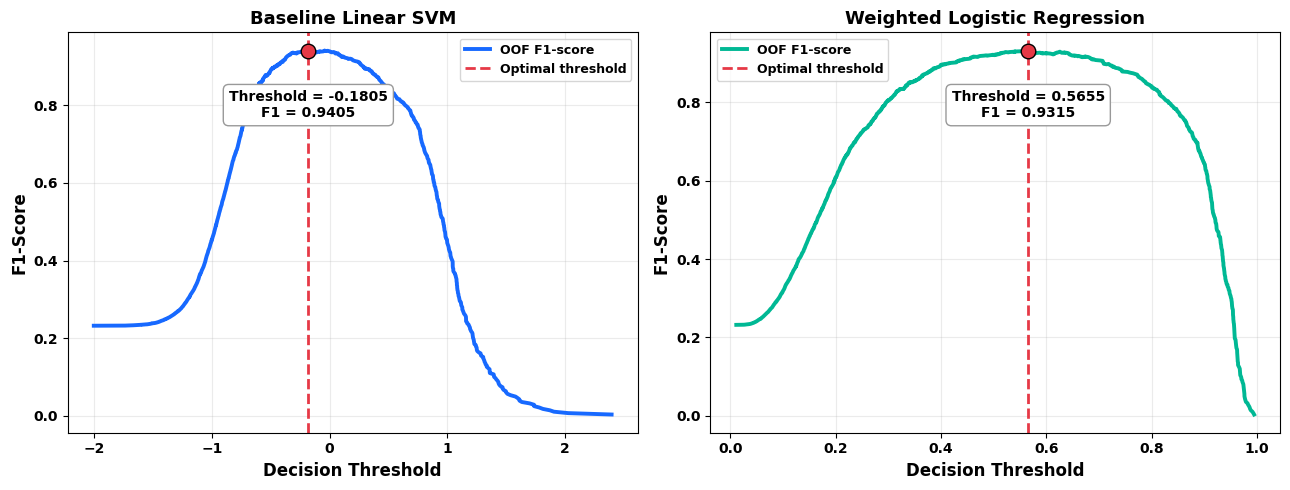

In [20]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#1769FF", "#00B894"]

for ax, (name, data), color in zip(
    axes, threshold_curves.items(), colors
):
    thresholds = data["thresholds"]
    f1 = data["f1"]

    best_idx = np.argmax(f1)
    best_t = thresholds[best_idx]
    best_f1 = f1[best_idx]

    ax.plot(
        thresholds, f1,
        color=color,
        linewidth=2.8,
        label="OOF F1-score"
    )

    ax.axvline(
        best_t,
        color="#E63946",
        linestyle="--",
        linewidth=2,
        label="Optimal threshold"
    )

    ax.scatter(
        best_t, best_f1,
        color="#E63946",
        s=110,
        edgecolor="black",
        linewidth=1,
        zorder=5
    )

    ax.annotate(
        f"Threshold = {best_t:.4f}\nF1 = {best_f1:.4f}",
        xy=(best_t, best_f1),
        xytext=(0, -48),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            fc="white",
            ec="#999999"
        )
    )

    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_xlabel(
        "Decision Threshold",
        fontsize=12,
        fontweight="bold"
    )
    ax.set_ylabel(
        "F1-Score",
        fontsize=12,
        fontweight="bold"
    )

    ax.grid(alpha=0.25)
    ax.legend(prop={"weight": "bold", "size": 9})

    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontweight("bold")

plt.tight_layout()

plt.savefig(
    "Figure_4_Threshold_Optimization.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_4_Threshold_Optimization.pdf",
    bbox_inches="tight"
)

plt.show()

**Section 4.7 — Independent Test-Set Evaluation**

###Step 4.7.1 — Train the Final Models

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Final models
final_models = {
    "Baseline Linear SVM": LinearSVC(
        random_state=42
    ),

    "Weighted Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

trained_models = {}

for name, classifier in final_models.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            norm="l2"
        )),
        ("classifier", classifier)
    ])

    # Fit only on training data
    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name}: Training completed")

    print(
        "TF-IDF features:",
        len(
            pipeline.named_steps[
                "tfidf"
            ].get_feature_names_out()
        )
    )

print("\nBoth final models trained successfully.")
print("Independent test set has not been evaluated.")

Baseline Linear SVM: Training completed
TF-IDF features: 10196
Weighted Logistic Regression: Training completed
TF-IDF features: 10196

Both final models trained successfully.
Independent test set has not been evaluated.


###Step 4.7.2 — Independent Test-Set Performance Evaluation

In [22]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    average_precision_score,
    confusion_matrix
)

# Use the exact thresholds selected using training OOF scores
svm_threshold = float(
    threshold_df.loc[
        threshold_df["Model"] == "Baseline Linear SVM",
        "Optimal Threshold"
    ].iloc[0]
)

lr_threshold = float(
    threshold_df.loc[
        threshold_df["Model"] == "Weighted Logistic Regression",
        "Optimal Threshold"
    ].iloc[0]
)

# Obtain independent test-set scores
svm_scores = trained_models[
    "Baseline Linear SVM"
].decision_function(X_test)

lr_scores = trained_models[
    "Weighted Logistic Regression"
].predict_proba(X_test)[:, 1]

# Four configurations
test_configurations = {
    "Baseline Linear SVM": (svm_scores, 0.0),
    "Optimized Linear SVM": (svm_scores, svm_threshold),
    "Weighted Logistic Regression": (lr_scores, 0.5),
    "Optimized Weighted LR": (lr_scores, lr_threshold)
}

test_results = []
test_predictions = {}

for name, (scores, threshold) in test_configurations.items():

    y_pred = (scores >= threshold).astype(int)

    test_predictions[name] = y_pred

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    test_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "AP": average_precision_score(y_test, scores),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

test_df = pd.DataFrame(test_results)

print("\nINDEPENDENT TEST-SET PERFORMANCE")
print("=" * 100)

print(
    test_df[
        [
            "Model", "Threshold", "Accuracy",
            "Precision", "Recall", "F1",
            "Balanced Accuracy", "MCC", "AP"
        ]
    ].round(4).to_string(index=False)
)

print("\nCONFUSION MATRIX COUNTS")
print("=" * 75)

print(
    test_df[
        ["Model", "TN", "FP", "FN", "TP"]
    ].to_string(index=False)
)

test_df.to_csv(
    "Table_6_Independent_Test_Results.csv",
    index=False
)

print("\nResults saved successfully.")


INDEPENDENT TEST-SET PERFORMANCE
                       Model  Threshold  Accuracy  Precision  Recall     F1  Balanced Accuracy    MCC     AP
         Baseline Linear SVM     0.0000    0.9914     0.9848  0.9489 0.9665             0.9734 0.9618 0.9908
        Optimized Linear SVM    -0.1805    0.9895     0.9565  0.9635 0.9600             0.9784 0.9539 0.9908
Weighted Logistic Regression     0.5000    0.9818     0.9041  0.9635 0.9329             0.9740 0.9230 0.9885
       Optimized Weighted LR     0.5655    0.9847     0.9231  0.9635 0.9429             0.9757 0.9343 0.9885

CONFUSION MATRIX COUNTS
                       Model  TN  FP  FN  TP
         Baseline Linear SVM 905   2   7 130
        Optimized Linear SVM 901   6   5 132
Weighted Logistic Regression 893  14   5 132
       Optimized Weighted LR 896  11   5 132

Results saved successfully.


###Step 4.7.3: Confusion Matrix Visualization

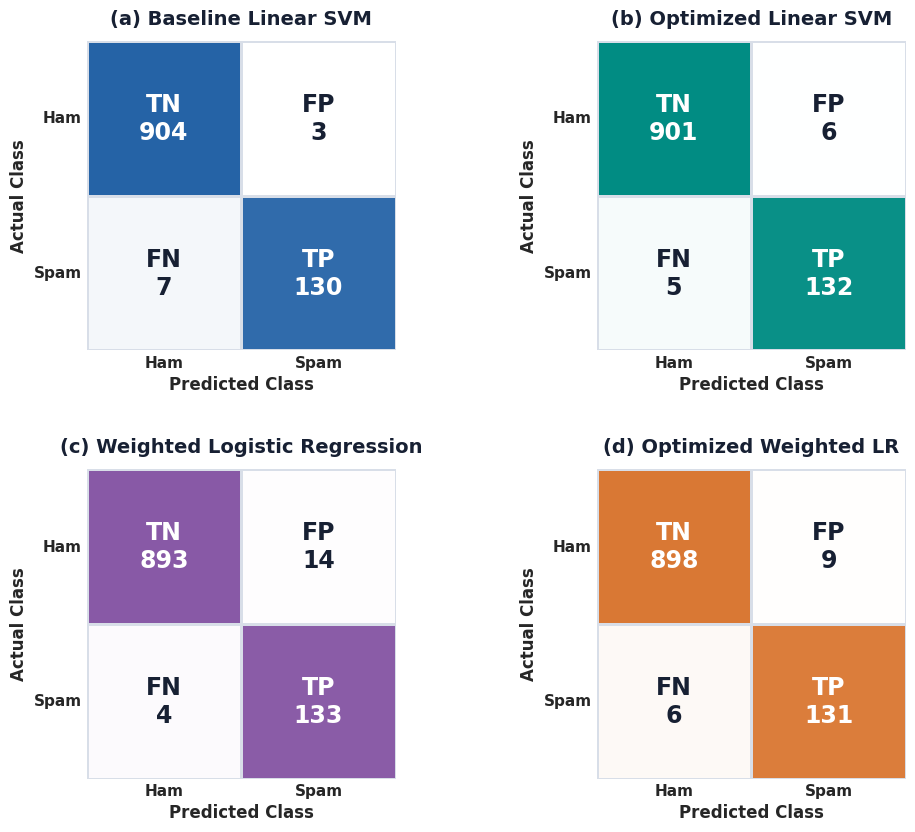

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

models_cm = {
    "(a) Baseline Linear SVM": [[904, 3], [7, 130]],
    "(b) Optimized Linear SVM": [[901, 6], [5, 132]],
    "(c) Weighted Logistic Regression": [[893, 14], [4, 133]],
    "(d) Optimized Weighted LR": [[898, 9], [6, 131]]
}

colors = [
    "#2563A6",  # Scientific blue
    "#008C83",  # Teal
    "#8757A5",  # Purple
    "#D97732"   # Burnt orange
]

sns.set_theme(style="white", font_scale=1.05)

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, matrix), color in zip(
    axes.flat, models_cm.items(), colors
):
    cm = np.array(matrix)

    # Row-normalized intensity; raw counts remain displayed
    normalized = cm / cm.sum(axis=1, keepdims=True)

    cmap = LinearSegmentedColormap.from_list(
        "custom", ["#FFFFFF", color]
    )

    sns.heatmap(
        normalized,
        cmap=cmap,
        vmin=0,
        vmax=1,
        square=True,
        cbar=False,
        annot=False,
        linewidths=2,
        linecolor="#D8DEE8",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    cell_labels = [
        ["TN", "FP"],
        ["FN", "TP"]
    ]

    for i in range(2):
        for j in range(2):
            text_color = (
                "white" if normalized[i, j] > 0.58
                else "#172033"
            )

            ax.text(
                j + 0.5,
                i + 0.5,
                f"{cell_labels[i][j]}\n{cm[i,j]}",
                ha="center",
                va="center",
                fontsize=17,
                fontweight="bold",
                color=text_color
            )

    ax.set_title(
        name,
        fontsize=14,
        fontweight="bold",
        pad=12,
        color="#172033"
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Actual Class",
        fontsize=12,
        fontweight="bold"
    )

    ax.tick_params(axis="both", labelsize=11, length=0)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight("bold")
        label.set_rotation(0)

plt.tight_layout(pad=2.5)

plt.savefig(
    "Figure_5_Confusion_Matrices_Q1.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    "Figure_5_Confusion_Matrices_Q1.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

### 4.7.4 Precision–Recall Curve Analysis

Times New Roman unavailable; using DejaVu Serif.
Install/register Times New Roman for exact font matching.


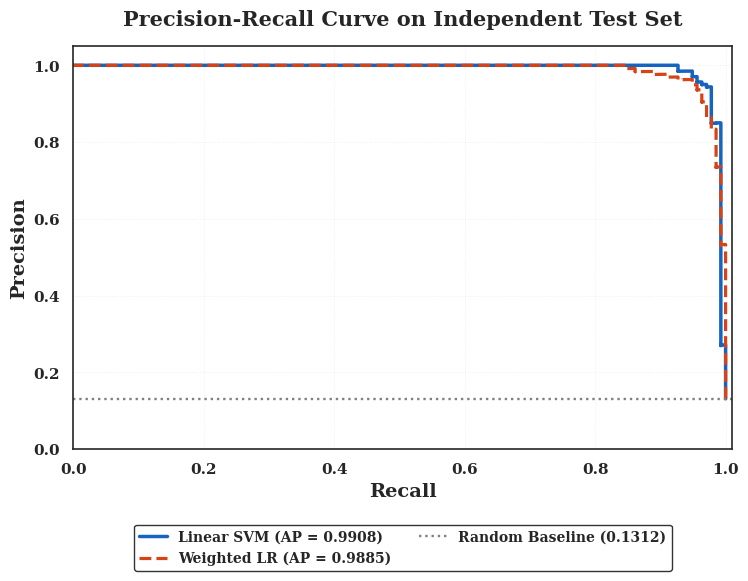


PRECISION-RECALL PERFORMANCE
                       Model  Average Precision
                  Linear SVM             0.9908
Weighted Logistic Regression             0.9885

Spam Prevalence: 0.1312

Figures saved successfully.


In [41]:

# ============================================================
# SECTION 4.7.4: PRECISION-RECALL CURVE ANALYSIS
# Single Publication-Quality Figure
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# STEP 1: Configure Times New Roman and bold text
# ------------------------------------------------------------

font_names = {f.name for f in font_manager.fontManager.ttflist}

if "Times New Roman" in font_names:
    chosen_font = "Times New Roman"
else:
    chosen_font = "DejaVu Serif"
    print("Times New Roman unavailable; using DejaVu Serif.")
    print("Install/register Times New Roman for exact font matching.")

plt.rcParams.update({
    "font.family": chosen_font,
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.linewidth": 1.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ------------------------------------------------------------
# STEP 2: Obtain prediction scores
# ------------------------------------------------------------

svm_scores = trained_models[
    "Baseline Linear SVM"
].decision_function(X_test)

lr_scores = trained_models[
    "Weighted Logistic Regression"
].predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# STEP 3: Calculate Precision-Recall curves
# ------------------------------------------------------------

svm_precision, svm_recall, _ = precision_recall_curve(
    y_test, svm_scores, pos_label=1
)

lr_precision, lr_recall, _ = precision_recall_curve(
    y_test, lr_scores, pos_label=1
)

# ------------------------------------------------------------
# STEP 4: Calculate Average Precision
# ------------------------------------------------------------

svm_ap = average_precision_score(y_test, svm_scores)
lr_ap = average_precision_score(y_test, lr_scores)

spam_prevalence = np.mean(np.asarray(y_test) == 1)

# ------------------------------------------------------------
# STEP 5: Generate a single PR curve figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.5, 6.5))

ax.step(
    svm_recall,
    svm_precision,
    where="post",
    color="#1565C0",
    linewidth=2.5,
    label=f"Linear SVM (AP = {svm_ap:.4f})"
)

ax.step(
    lr_recall,
    lr_precision,
    where="post",
    color="#D84315",
    linestyle="--",
    linewidth=2.3,
    label=f"Weighted LR (AP = {lr_ap:.4f})"
)

ax.axhline(
    y=spam_prevalence,
    color="gray",
    linestyle=":",
    linewidth=1.7,
    label=f"Random Baseline ({spam_prevalence:.4f})"
)

# Labels and title
ax.set_xlabel(
    "Recall", fontsize=14, fontweight="bold"
)

ax.set_ylabel(
    "Precision", fontsize=14, fontweight="bold"
)

ax.set_title(
    "Precision-Recall Curve on Independent Test Set",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.05)

ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.set_yticks(np.arange(0, 1.01, 0.2))

ax.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.3
)

# Bold tick labels
ax.tick_params(axis="both", labelsize=11)

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

# Legend below the plot to prevent overlap
legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=2,
    fontsize=10,
    frameon=True,
    edgecolor="black"
)

for label in legend.get_texts():
    label.set_fontweight("bold")
    label.set_fontfamily(chosen_font)

# Reserve space below for the legend
fig.subplots_adjust(bottom=0.28, top=0.90)

# ------------------------------------------------------------
# STEP 6: Save PNG and PDF
# ------------------------------------------------------------

fig.savefig(
    "PR_Curve_Final_Conference.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "PR_Curve_Final_Conference.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# STEP 7: Print performance results
# ------------------------------------------------------------

pr_results = pd.DataFrame({
    "Model": [
        "Linear SVM",
        "Weighted Logistic Regression"
    ],
    "Average Precision": [
        svm_ap,
        lr_ap
    ]
})

print("\nPRECISION-RECALL PERFORMANCE")
print(pr_results.round(4).to_string(index=False))

print("\nSpam Prevalence:", round(spam_prevalence, 4))
print("\nFigures saved successfully.")


**4.8. Statistical Significance Analysis of Classifier Performance**

###Step 4.8.1 — McNemar's Statistical Significance Test

In [34]:
import numpy as np
import pandas as pd
from scipy.stats import binomtest

# Model pairs for statistical comparison
model_pairs = [
    ("Baseline Linear SVM", "Optimized Linear SVM"),
    ("Weighted Logistic Regression", "Optimized Weighted LR"),
    ("Baseline Linear SVM", "Weighted Logistic Regression"),
    ("Baseline Linear SVM", "Optimized Weighted LR")
]

statistical_results = []

for model_a, model_b in model_pairs:

    pred_a = np.asarray(test_predictions[model_a])
    pred_b = np.asarray(test_predictions[model_b])
    actual = np.asarray(y_test)

    # Correct and incorrect predictions
    correct_a = (pred_a == actual)
    correct_b = (pred_b == actual)

    # Discordant pairs
    b = np.sum(correct_a & ~correct_b)
    c = np.sum(~correct_a & correct_b)

    # Exact McNemar test
    if b + c > 0:
        p_value = binomtest(
            min(b, c),
            n=b + c,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    else:
        p_value = 1.0

    statistical_results.append({
        "Model A": model_a,
        "Model B": model_b,
        "A Correct / B Wrong": b,
        "A Wrong / B Correct": c,
        "Discordant Pairs": b + c,
        "Exact p-value": p_value,
        "Significant (p < 0.05)": (
            "Yes" if p_value < 0.05 else "No"
        )
    })

mcnemar_df = pd.DataFrame(statistical_results)

print("\nMcNEMAR'S EXACT TEST RESULTS")
print("=" * 110)

print(
    mcnemar_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

mcnemar_df.to_csv(
    "Table_7_McNemar_Statistical_Test.csv",
    index=False
)

print("\nStatistical analysis completed.")
print("Results saved for Table 7.")


McNEMAR'S EXACT TEST RESULTS
                     Model A                      Model B  A Correct / B Wrong  A Wrong / B Correct  Discordant Pairs  Exact p-value Significant (p < 0.05)
         Baseline Linear SVM         Optimized Linear SVM                    4                    2                 6       0.687500                     No
Weighted Logistic Regression        Optimized Weighted LR                    0                    3                 3       0.250000                     No
         Baseline Linear SVM Weighted Logistic Regression                   13                    3                16       0.021271                    Yes
         Baseline Linear SVM        Optimized Weighted LR                   10                    3                13       0.092285                     No

Statistical analysis completed.
Results saved for Table 7.


###Step 4.8.2 —Holm Multiple-Comparison Correction

In [35]:
import pandas as pd
from statsmodels.stats.multitest import multipletests

# Original exact McNemar p-values
p_values = mcnemar_df["Exact p-value"].to_numpy()

# Holm correction for four comparisons
reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

# Prepare publication table
table7 = mcnemar_df[
    [
        "Model A",
        "Model B",
        "A Correct / B Wrong",
        "A Wrong / B Correct",
        "Discordant Pairs",
        "Exact p-value"
    ]
].copy()

table7["Holm-adjusted p-value"] = p_adjusted

table7["Significant after correction"] = [
    "Yes" if r else "No" for r in reject
]

print("\nTABLE 7: STATISTICAL SIGNIFICANCE ANALYSIS")
print("=" * 120)

print(
    table7.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

table7.to_csv(
    "Table_7_Statistical_Significance.csv",
    index=False
)

print("\nTable 7 saved successfully.")


TABLE 7: STATISTICAL SIGNIFICANCE ANALYSIS
                     Model A                      Model B  A Correct / B Wrong  A Wrong / B Correct  Discordant Pairs  Exact p-value  Holm-adjusted p-value Significant after correction
         Baseline Linear SVM         Optimized Linear SVM                    4                    2                 6       0.687500               0.687500                           No
Weighted Logistic Regression        Optimized Weighted LR                    0                    3                 3       0.250000               0.500000                           No
         Baseline Linear SVM Weighted Logistic Regression                   13                    3                16       0.021271               0.085083                           No
         Baseline Linear SVM        Optimized Weighted LR                   10                    3                13       0.092285               0.276855                           No

Table 7 saved successfully.


**Section 4.9 — Error Analysis and Misclassification Patterns**

###Step 4.9.1 — Identify Misclassified SMS Messages

In [36]:
import pandas as pd
import numpy as np

# Baseline Linear SVM predictions and scores
svm_model = trained_models["Baseline Linear SVM"]

svm_predictions = test_predictions["Baseline Linear SVM"]
svm_scores = svm_model.decision_function(X_test)

# Create error analysis dataframe
error_df = pd.DataFrame({
    "Message": np.asarray(X_test),
    "Actual": np.asarray(y_test),
    "Predicted": np.asarray(svm_predictions),
    "Decision Score": svm_scores
})

# Identify misclassified messages
errors = error_df[
    error_df["Actual"] != error_df["Predicted"]
].copy()

# Categorize errors
errors["Error Type"] = np.where(
    (errors["Actual"] == 0) &
    (errors["Predicted"] == 1),
    "False Positive",
    "False Negative"
)

# Arrange columns
errors = errors[
    [
        "Error Type",
        "Actual",
        "Predicted",
        "Decision Score",
        "Message"
    ]
]

print("\nBASELINE LINEAR SVM — MISCLASSIFIED MESSAGES")
print("=" * 110)

pd.set_option("display.max_colwidth", 200)

print(
    errors.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nERROR DISTRIBUTION")
print(errors["Error Type"].value_counts())

errors.to_csv(
    "Table_8_SVM_Error_Analysis.csv",
    index=False
)

print("\nError analysis saved successfully.")


BASELINE LINEAR SVM — MISCLASSIFIED MESSAGES
    Error Type  Actual  Predicted  Decision Score                                                                                                                                                      Message
False Negative       1          0         -1.0325                                                                               Sorry I missed your call let's talk when you have the time. I'm on 07090201529
False Positive       0          1          0.1291                                                                                                                                      K k:) sms chat with me.
False Negative       1          0         -0.2272                   thesmszone.com lets you send free anonymous and masked messages..im sending this message from there..do you see the potential for abuse???
False Negative       1          0         -0.4164     Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fan

###4.9.2 Message Length Analysis

In [37]:
import numpy as np
import pandas as pd

# Work with the existing test-set error dataframe
length_df = error_df.copy()

length_df["Character Count"] = (
    length_df["Message"].astype(str).str.len()
)

length_df["Word Count"] = (
    length_df["Message"]
    .astype(str)
    .str.split()
    .str.len()
)

length_df["Classification Group"] = np.select(
    [
        (length_df["Actual"] == 0) &
        (length_df["Predicted"] == 1),

        (length_df["Actual"] == 1) &
        (length_df["Predicted"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correctly Classified"
)

length_summary = (
    length_df
    .groupby("Classification Group")
    .agg(
        Messages=("Message", "count"),
        Mean_Characters=("Character Count", "mean"),
        Median_Characters=("Character Count", "median"),
        Mean_Words=("Word Count", "mean"),
        Median_Words=("Word Count", "median")
    )
    .round(2)
    .reset_index()
)

print("\nMESSAGE LENGTH ANALYSIS")
print("=" * 90)

print(length_summary.to_string(index=False))

length_summary.to_csv(
    "Table_8_Message_Length_Analysis.csv",
    index=False
)

print("\nAnalysis completed.")


MESSAGE LENGTH ANALYSIS
Classification Group  Messages  Mean_Characters  Median_Characters  Mean_Words  Median_Words
Correctly Classified      1035            79.07               60.0       15.33          12.0
      False Negative         7           128.14              148.0       24.00          28.0
      False Positive         2            25.00               25.0        5.50           5.5

Analysis completed.


###Step 4.9.3 — Class-Specific Message Length Analysis

In [38]:
import numpy as np
import pandas as pd

# Use the existing test-set dataframe
class_length_df = error_df.copy()

class_length_df["Characters"] = (
    class_length_df["Message"].astype(str).str.len()
)

class_length_df["Words"] = (
    class_length_df["Message"]
    .astype(str)
    .str.split()
    .str.len()
)

# Assign TP, TN, FP, FN categories
conditions = [
    (class_length_df["Actual"] == 0) &
    (class_length_df["Predicted"] == 0),

    (class_length_df["Actual"] == 0) &
    (class_length_df["Predicted"] == 1),

    (class_length_df["Actual"] == 1) &
    (class_length_df["Predicted"] == 0),

    (class_length_df["Actual"] == 1) &
    (class_length_df["Predicted"] == 1)
]

class_length_df["Outcome"] = np.select(
    conditions,
    [
        "True Negative (Ham)",
        "False Positive (Ham)",
        "False Negative (Spam)",
        "True Positive (Spam)"
    ],
    default="Unknown"
)

class_specific_summary = (
    class_length_df
    .groupby("Outcome")
    .agg(
        Messages=("Message", "count"),
        Mean_Characters=("Characters", "mean"),
        Median_Characters=("Characters", "median"),
        Mean_Words=("Words", "mean"),
        Median_Words=("Words", "median")
    )
    .round(2)
)

# Logical ordering
order = [
    "True Negative (Ham)",
    "False Positive (Ham)",
    "True Positive (Spam)",
    "False Negative (Spam)"
]

class_specific_summary = (
    class_specific_summary.reindex(order)
)

print("\nCLASS-SPECIFIC MESSAGE LENGTH ANALYSIS")
print("=" * 95)

print(class_specific_summary.to_string())

class_specific_summary.to_csv(
    "Table_8_Class_Specific_Length_Analysis.csv"
)

print("\nClass-specific analysis completed.")


CLASS-SPECIFIC MESSAGE LENGTH ANALYSIS
                       Messages  Mean_Characters  Median_Characters  Mean_Words  Median_Words
Outcome                                                                                      
True Negative (Ham)         905            71.30               52.0       14.28          11.0
False Positive (Ham)          2            25.00               25.0        5.50           5.5
True Positive (Spam)        130           133.16              146.0       22.65          24.0
False Negative (Spam)         7           128.14              148.0       24.00          28.0

Class-specific analysis completed.


**4.10. Prototype Development and User Interface**

###Step 4.10.1 Gradio Environment Setup

In [39]:

!pip install -q gradio
import gradio as gr

print("Gradio installed successfully.")
print("Gradio version:", gr.__version__)

print("Trained models available:", list(trained_models.keys()))


Gradio installed successfully.
Gradio version: 6.29.0
Trained models available: ['Baseline Linear SVM', 'Weighted Logistic Regression']


###Step 4.10.2 — Develop the SMS Spam Detection Front End

In [31]:

import gradio as gr
import html
import numpy as np

svm_model = trained_models["Baseline Linear SVM"]

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    font-family: 'Segoe UI', sans-serif !important;
}
.hero {
    background: linear-gradient(120deg, #10274f, #2563eb);
    border-radius: 18px;
    padding: 32px;
    color: white;
    margin-bottom: 18px;
}
.hero h1 { color: white !important; font-size: 32px; margin: 0; }
.hero p { color: #dbeafe !important; font-size: 15px; }
.panel {
    border-radius: 16px;
    padding: 22px;
    border: 1px solid #dce4f0;
    background: #f8fafc;
}
.result-card {
    padding: 26px;
    border-radius: 16px;
    text-align: center;
    margin-top: 8px;
}
.spam-card {
    background: #fff1f2;
    border: 2px solid #fda4af;
    color: #9f1239;
}
.ham-card {
    background: #ecfdf5;
    border: 2px solid #86efac;
    color: #166534;
}
.score-track {
    background: #e2e8f0;
    height: 14px;
    border-radius: 10px;
    position: relative;
    overflow: hidden;
    margin: 14px 0;
}
.score-fill {
    height: 100%;
    background: #2563eb;
    border-radius: 10px;
}
.metric {
    display: inline-block;
    background: #eff6ff;
    color: #1e40af;
    padding: 8px 14px;
    margin: 5px;
    border-radius: 10px;
    font-size: 13px;
}
"""

def enhanced_predict(message):
    if not message or not message.strip():
        return (
            "<div class='panel'>Enter an SMS message to begin analysis.</div>",
            "<div class='panel'>No message analyzed yet.</div>"
        )

    prediction = int(svm_model.predict([message])[0])
    score = float(svm_model.decision_function([message])[0])

    is_spam = prediction == 1
    label = "SPAM DETECTED" if is_spam else "LEGITIMATE MESSAGE"
    symbol = "⚠️" if is_spam else "✅"
    card_class = "spam-card" if is_spam else "ham-card"

    # Visual position of the score on a fixed -2 to +2 scale.
    # Values outside the display range are clipped.
    gauge_position = np.clip((score + 2) / 4 * 100, 0, 100)

    result_html = f"""
    <div class="result-card {card_class}">
        <div style="font-size:42px">{symbol}</div>
        <h2 style="margin:8px 0">{label}</h2>
        <p>Classification by TF-IDF + Linear SVM</p>
    </div>
    """

    details_html = f"""
    <div class="panel">
        <h3>Classification Analysis</h3>
        <p><b>SVM Decision Score:</b> {score:+.4f}</p>
        <div class="score-track">
            <div class="score-fill"
                 style="width:{gauge_position:.1f}%"></div>
        </div>
        <p style="font-size:12px">
            Display scale: −2 (Ham side) to +2 (Spam side).
            Decision boundary: 0.
            The bar position is not a probability.
        </p>
        <hr>
        <h3>Message Statistics</h3>
        <span class="metric">
            Characters: {len(message)}
        </span>
        <span class="metric">
            Words: {len(message.split())}
        </span>
        <span class="metric">
            Model: Linear SVM
        </span>
        <p style="font-size:12px;margin-top:14px">
            Prediction is generated from the trained model.
            It does not guarantee message safety.
        </p>
    </div>
    """

    return result_html, details_html


with gr.Blocks(
    title="Intelligent SMS Spam Detection",
    css=custom_css,
    theme=gr.themes.Soft()
) as enhanced_demo:

    gr.HTML("""
    <div class="hero">
        <h1>🛡️ Intelligent SMS Spam Detection</h1>
        <p>Machine Learning-Based Message Classification Dashboard</p>
        <p>TF-IDF Feature Extraction | Linear Support Vector Machine</p>
    </div>
    """)

    with gr.Row(equal_height=False):

        with gr.Column(scale=5):
            gr.Markdown("### Message Input")

            sms_input = gr.Textbox(
                label="SMS Message",
                placeholder="Enter or paste an SMS message...",
                lines=8
            )

            with gr.Row():
                analyze_btn = gr.Button(
                    "Analyze Message",
                    variant="primary"
                )
                clear_btn = gr.Button("Clear")

            gr.Examples(
                examples=[
                    ["Hi, are we meeting at 5 PM today?"],
                    ["Congratulations! You have won a free prize. Claim now!"],
                    ["Please call me when you reach home."],
                    ["URGENT! Claim your cash reward. Reply WIN now."]
                ],
                inputs=sms_input
            )

        with gr.Column(scale=5):
            gr.Markdown("### Detection Result")

            result = gr.HTML(
                "<div class='panel'>Awaiting message analysis...</div>"
            )

            details = gr.HTML(
                "<div class='panel'>Decision score and message statistics will appear here.</div>"
            )

    analyze_btn.click(
        enhanced_predict,
        inputs=sms_input,
        outputs=[result, details]
    )

    clear_btn.click(
        lambda: (
            "",
            "<div class='panel'>Awaiting message analysis...</div>",
            "<div class='panel'>No message analyzed yet.</div>"
        ),
        outputs=[sms_input, result, details]
    )

    gr.Markdown(
        "**Research Prototype** — Predictions are generated using "
        "the baseline Linear SVM classifier evaluated in the study."
    )

enhanced_demo.launch(share=True, debug=True)


/tmp/ipykernel_2342/1769285839.py:129: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://c1951a9f44c44b5bc6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://c1951a9f44c44b5bc6.gradio.live


###4.10.3 Model Serialization and Deployment Preparation

In [32]:

import joblib
import os

# Save the complete trained TF-IDF + Linear SVM pipeline
model_path = "sms_spam_linear_svm.joblib"

joblib.dump(
    trained_models["Baseline Linear SVM"],
    model_path
)

# Verify the saved model
loaded_model = joblib.load(model_path)

test_message = "Congratulations! You have won a free prize. Claim now!"

original_prediction = trained_models["Baseline Linear SVM"].predict(
    [test_message]
)[0]

loaded_prediction = loaded_model.predict(
    [test_message]
)[0]

print("Model saved:", model_path)
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
print("Original prediction:", original_prediction)
print("Loaded prediction:", loaded_prediction)
print("Predictions match:", original_prediction == loaded_prediction)


Model saved: sms_spam_linear_svm.joblib
File size: 297.55 KB
Original prediction: 1
Loaded prediction: 1
Predictions match: True


### 4.10.4 Serialized Model Verification

In [42]:

# 4.10.4 Serialized Model Verification

import joblib
import os

model_path = "sms_spam_linear_svm.joblib"

loaded_model = joblib.load(model_path)

print("Model loaded successfully.")
print("File size (KB):",
      round(os.path.getsize(model_path) / 1024, 2))

print("\nPipeline:")
print(loaded_model)

# Verify model prediction
sample_sms = ["Congratulations! Claim your free prize now!"]

prediction = loaded_model.predict(sample_sms)

print("\nSample prediction:", prediction[0])
print("Predicted class:",
      "SPAM" if prediction[0] == 1 else "HAM")


Model loaded successfully.
File size (KB): 297.55

Pipeline:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, min_df=2, ngram_range=(1, 2))),
                ('classifier', LinearSVC(random_state=42))])

Sample prediction: 1
Predicted class: SPAM


### 4.10.5 Cloud Deployment Environment Preparation

In [47]:

# ============================================================
# 4.10.5 CLOUD DEPLOYMENT ENVIRONMENT PREPARATION
# ============================================================

import sys
import subprocess
import sklearn
import joblib
import importlib.metadata as metadata

# Install Streamlit if not already installed
try:
    import streamlit as st
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "streamlit"
    ])
    import streamlit as st

print("STREAMLIT DEPLOYMENT ENVIRONMENT")
print("-" * 50)

print("Python version:", sys.version.split()[0])
print("Scikit-learn version:", sklearn.__version__)
print("Joblib version:", joblib.__version__)
print("Streamlit version:", metadata.version("streamlit"))

print("-" * 50)
print("Environment verification completed.")


STREAMLIT DEPLOYMENT ENVIRONMENT
--------------------------------------------------
Python version: 3.13.16
Scikit-learn version: 1.6.1
Joblib version: 1.6.0
Streamlit version: 1.65.0
--------------------------------------------------
Environment verification completed.


### 4.10.6 STREAMLIT-BASED WEB APPLICATION DEVELOPMENT

In [49]:

# ============================================================
# 4.10.6 STREAMLIT-BASED WEB APPLICATION DEVELOPMENT
# ============================================================

import os

app_code = '''
import streamlit as st
import joblib

# ------------------------------------------------------------
# Page configuration
# ------------------------------------------------------------

st.set_page_config(
    page_title="SMS Spam Detection System",
    page_icon="📩",
    layout="centered"
)

# ------------------------------------------------------------
# Load trained TF-IDF + Linear SVM model
# ------------------------------------------------------------

@st.cache_resource
def load_model():
    return joblib.load("sms_spam_linear_svm.joblib")

model = load_model()

# ------------------------------------------------------------
# Dashboard
# ------------------------------------------------------------

st.title("SMS Spam Detection System")

st.write(
    "Cloud-Based SMS Classification Using "
    "TF-IDF and Linear Support Vector Machine"
)

st.divider()

st.subheader("Enter SMS Message")

message = st.text_area(
    "SMS Text",
    height=160,
    placeholder="Type or paste your SMS message here..."
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

if st.button("Classify SMS", type="primary"):

    if not message.strip():
        st.warning("Please enter an SMS message.")

    else:
        prediction = int(model.predict([message])[0])

        score = float(
            model.decision_function([message])[0]
        )

        if prediction == 1:
            st.error("SPAM - Suspicious Message")
        else:
            st.success("HAM - Legitimate Message")

        st.metric(
            label="SVM Decision Score",
            value=f"{score:.4f}"
        )

        st.caption(
            "The SVM decision score is a classification "
            "margin, not a calibrated probability."
        )

# ------------------------------------------------------------
# Example SMS messages
# ------------------------------------------------------------

st.divider()

st.subheader("Example SMS Messages")

examples = [
    "Hi, are we meeting today?",
    "Congratulations! Claim your free prize now!",
    "Please call me when you reach home.",
    "URGENT! You have won a cash reward. Reply now!"
]

for i, example in enumerate(examples, start=1):
    st.write(f"{i}. {example}")

# ------------------------------------------------------------
# Footer
# ------------------------------------------------------------

st.divider()

st.caption(
    "Research Prototype | TF-IDF + Linear SVM"
)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("STREAMLIT APPLICATION DEVELOPMENT")
print("-" * 50)
print("Application file created successfully.")
print("Filename: app.py")
print("File size:", os.path.getsize("app.py"), "bytes")


STREAMLIT APPLICATION DEVELOPMENT
--------------------------------------------------
Application file created successfully.
Filename: app.py
File size: 2520 bytes


### 4.10.7 Dependency and Cloud Configuration File Generation

In [50]:

# ============================================================
# 4.10.7 DEPENDENCY AND CLOUD CONFIGURATION FILE GENERATION
# ============================================================

import os
import sklearn
import joblib
import importlib.metadata as metadata

# ------------------------------------------------------------
# Step 1: Generate requirements.txt
# ------------------------------------------------------------

streamlit_version = metadata.version("streamlit")

requirements = f"""streamlit=={streamlit_version}
scikit-learn=={sklearn.__version__}
joblib=={joblib.__version__}
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

# ------------------------------------------------------------
# Step 2: Generate README.md
# ------------------------------------------------------------

readme = """# SMS Spam Detection System

## Cloud-Based SMS Spam Detection Using TF-IDF and Linear SVM

This research prototype classifies SMS messages as
Ham (legitimate) or Spam (unwanted).

## Machine Learning Framework

- Feature Extraction: TF-IDF
- Classifier: Linear Support Vector Machine
- Classification: Binary (Ham/Spam)
- Application Framework: Streamlit
- Cloud Platform: Streamlit Community Cloud

## Model Deployment

The application uses a previously trained
TF-IDF + Linear SVM pipeline saved using Joblib.

The SVM decision score represents a classification
margin and is not a calibrated probability.
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# ------------------------------------------------------------
# Step 3: Verify generated files
# ------------------------------------------------------------

print("STREAMLIT CLOUD CONFIGURATION")
print("-" * 50)

for filename in ["requirements.txt", "README.md"]:
    print(
        filename,
        "Created:",
        os.path.exists(filename)
    )

print("\nDEPENDENCIES")
print(requirements)

print("Cloud configuration completed.")


STREAMLIT CLOUD CONFIGURATION
--------------------------------------------------
requirements.txt Created: True
README.md Created: True

DEPENDENCIES
streamlit==1.65.0
scikit-learn==1.6.1
joblib==1.6.0

Cloud configuration completed.


### 4.10.8 Cloud Deployment Package Preparation

In [51]:

# ============================================================
# 4.10.8 STREAMLIT CLOUD DEPLOYMENT PACKAGE PREPARATION
# ============================================================

import os
import zipfile
from google.colab import files

deployment_files = [
    "app.py",
    "requirements.txt",
    "README.md",
    "sms_spam_linear_svm.joblib"
]

print("DEPLOYMENT FILE VERIFICATION")
print("-" * 50)

# Step 1: Verify all deployment files
for filename in deployment_files:

    if not os.path.isfile(filename):
        raise FileNotFoundError(
            f"Missing file: {filename}"
        )

    size_kb = os.path.getsize(filename) / 1024

    print(f"{filename}: {size_kb:.2f} KB")

# Step 2: Create Streamlit deployment package
zip_filename = "SMS_Spam_Streamlit_Deployment.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in deployment_files:
        zipf.write(filename, arcname=filename)

# Step 3: Verify the ZIP
with zipfile.ZipFile(zip_filename, "r") as zipf:

    if zipf.testzip() is not None:
        raise RuntimeError("ZIP verification failed.")

    print("\nFILES INSIDE ZIP:")

    for filename in zipf.namelist():
        print(filename)

print("\nDeployment package created successfully.")

print(
    "ZIP size:",
    round(os.path.getsize(zip_filename) / 1024, 2),
    "KB"
)

# Step 4: Download package
files.download(zip_filename)


DEPLOYMENT FILE VERIFICATION
--------------------------------------------------
app.py: 2.46 KB
requirements.txt: 0.05 KB
README.md: 0.59 KB
sms_spam_linear_svm.joblib: 297.55 KB

FILES INSIDE ZIP:
app.py
requirements.txt
README.md
sms_spam_linear_svm.joblib

Deployment package created successfully.
ZIP size: 141.64 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>